# Arquitecturas de redes recurrentes para pronosticar (PyTorch)

En la presentación **Arquitecturas y práctica** vimos que una red recurrente se puede usar con cuatro arquitecturas, según qué entra a la red y qué sale de ella:

| Arquitectura | Qué entra | Qué sale |
|---|---|---|
| 1. Secuencia → vector | una serie | un solo resultado, al final (aquí, el día de mañana) |
| 2. Secuencia → secuencia | una serie | una predicción en cada paso (en cada uno, el día siguiente) |
| 3. Vector → secuencia | unos pocos números | una serie, generada un valor por paso (aquí, 14 días) |
| 4. Codificador–decodificador | una serie | otra serie, con otro largo (aquí, 14 días) |

En este notebook programamos las cuatro con **un mismo problema y un mismo dataset**, para que lo único que cambie de una sección a otra sea la arquitectura.

**El problema.** Tenemos el registro de cuántas personas entraron al metro de Chicago cada día durante los últimos años (es el mismo dataset del notebook de la red recurrente simple; abajo lo explicamos de nuevo). La empresa de transporte de Chicago (CTA) le hace dos preguntas a esos datos:

- **¿Cuánta gente viajará mañana?** Quien opera el metro lo pregunta cada noche, por ejemplo para reforzar una línea. Es un solo número, como en los notebooks anteriores.
- **¿Cuánta gente viajará en cada uno de los próximos 14 días?** Quien arma los turnos del personal y la programación de los trenes lo hace con unas dos semanas de anticipación, así que necesita 14 números.

**El plan.**

| Etapa | Qué hacemos | Pregunta que responde |
|---|---|---|
| 3 | Arquitectura 1: secuencia → vector | mañana |
| 4 | Arquitectura 2: secuencia → secuencia | mañana (con una predicción en cada paso) |
| 5 | Usar la red de un día 14 veces seguidas (paso a paso) | 14 días |
| 6 | Arquitectura 3: vector → secuencia | 14 días |
| 7 | Arquitectura 4: codificador–decodificador | 14 días |
| 8 | Comparar las tres formas de pronosticar 14 días | — |

Cada arquitectura tiene su propia sección con:

1. **La idea:** qué entra, qué sale y en qué situación del problema tiene sentido.
2. **Qué cambia** frente a la anterior, en una tabla.
3. **El esquema** de la presentación, explicado.
4. **Los ejemplos:** una tabla y una gráfica que muestran quién es X (lo que entra) y quién es y (lo que debe salir).
5. **La red**, explicada línea por línea, su entrenamiento y **su pronóstico** en un ejemplo que la red nunca vio.

Todas usan celdas **GRU** (del notebook de LSTM y GRU). La clase para entrenar es la de los notebooks anteriores, así que va sin explicación aparte.

## Etapa 1: Se carga la base de datos

In [1]:
import copy
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from tqdm import tqdm

INDIGO, TEAL, CORAL = "#3A47B5", "#0B8570", "#C03F32"   # colores de la presentación: lo que entra, lo que sale y el pronóstico

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


In [2]:
data_dir = Path("data")
csv_path = data_dir / "ridership" / "CTA_-_Ridership_-_Daily_Boarding_Totals.csv"
if not csv_path.exists():
    data_dir.mkdir(exist_ok=True)
    tgz_path, _ = urllib.request.urlretrieve("https://github.com/ageron/data/raw/main/ridership.tgz",
                                             data_dir / "ridership.tgz")
    with tarfile.open(tgz_path) as f:
        f.extractall(data_dir, filter="data")

df = pd.read_csv(csv_path, parse_dates=["service_date"], date_format="%m/%d/%Y")
df.columns = ["date", "day_type", "bus", "rail", "total"]
df = df.sort_values("date").set_index("date")
df = df.drop("total", axis=1)      # total = bus + rail, no aporta nada nuevo
df = df.drop_duplicates()          # el archivo trae algunos días repetidos
rail = df["rail"]
rail.head()

date
2001-01-01    126455
2001-01-02    501952
2001-01-03    536432
2001-01-04    550011
2001-01-05    557917
Name: rail, dtype: int64

### ¿De qué trata el dataset?

La CTA publica, desde 2001, **cuántas personas entraron a su sistema cada día**. Cada fila del archivo es un día y tiene cuatro columnas:

- `date`: la fecha.
- `day_type`: el tipo de día. `W` es un día laboral (lunes a viernes), `A` es sábado y `U` es domingo o festivo.
- `bus`: cuántas personas subieron a los buses ese día.
- `rail`: cuántas personas entraron al metro ese día. **Esta es la serie que vamos a pronosticar.**

Así que la serie es una lista de números, uno por día: $x_1, x_2, x_3, \dots$, donde cada número es la cantidad de personas que usaron el metro ese día. Veamos cómo se ve, primero en cuatro años y luego en tres semanas:

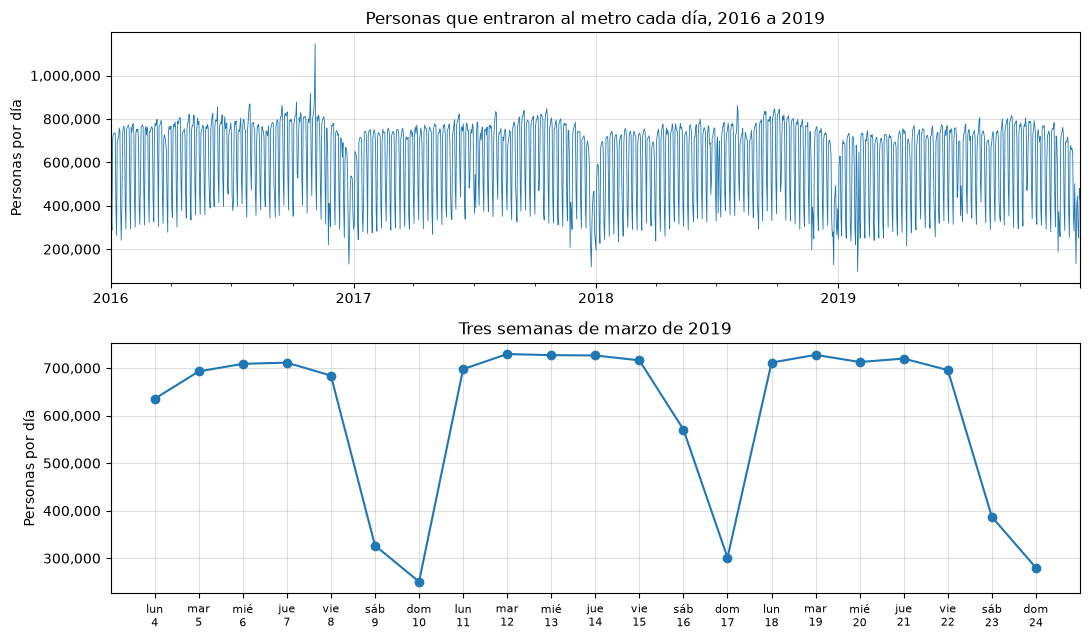

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5))
rail["2016":"2019"].plot(ax=ax1, lw=0.6)
ax1.set_title("Personas que entraron al metro cada día, 2016 a 2019"); ax1.set_xlabel(""); ax1.grid(alpha=0.4)

three_weeks = rail["2019-03-04":"2019-03-24"]
ax2.plot(three_weeks.index, three_weeks.values, "o-")
ax2.set_xticks(three_weeks.index)
ax2.set_xticklabels([f"{['lun', 'mar', 'mié', 'jue', 'vie', 'sáb', 'dom'][d.day_of_week]}\n{d.day}" for d in three_weeks.index], fontsize=8)
ax2.set_title("Tres semanas de marzo de 2019"); ax2.grid(alpha=0.4)
for ax in (ax1, ax2):
    ax.set_ylabel("Personas por día")
    ax.yaxis.set_major_formatter(lambda v, pos: f"{v:,.0f}")   # 700,000 en vez de 0.7 × 1e6
plt.tight_layout(); plt.show()

Lo que hay que notar:

- **Un patrón semanal muy marcado:** de lunes a viernes entran unas 700 000 a 800 000 personas (la gente va a trabajar y a estudiar); el sábado baja a unas 430 000 y el domingo a unas 320 000. Ese patrón se repite cada 7 días.
- **Los festivos** se parecen a un domingo: son los picos hacia abajo que aparecen sueltos en la gráfica de arriba (Navidad, Año Nuevo, Día de Acción de Gracias…).
- **El nivel cambia despacio:** en diciembre y enero viaja menos gente (vacaciones y frío), y de un año a otro el promedio baja poco a poco: de unas 650 000 personas por día en 2016 a unas 600 000 en 2019.

Por eso, para pronosticar, la red tiene que saber **en qué día de la semana va** y **cuál es el nivel reciente**. Con **56 días** de historia (8 semanas) ve el patrón semanal ocho veces y sabe cuánta gente está viajando últimamente. Esa es la ventana que usamos: **la red lee 56 días** y pronostica el día siguiente o los 14 siguientes, según la pregunta.

### Entrenamiento, validación y test

Dividimos en el tiempo: 2016 a 2018 para entrenar, enero a mayo de 2019 para validar y junio a diciembre de 2019 para test. Cada periodo de validación y test empieza con los 56 días anteriores, para que su primera ventana esté completa.

In [4]:
window_length, horizon = 56, 14   # la red lee 56 días; las dos semanas son 14 días

def period(start, end):
    # Los días entre start y end, más los window_length días anteriores
    first = rail.index.get_loc(rail[start:].index[0])
    last = rail.index.get_loc(rail[:end].index[-1])
    return rail.iloc[max(first - window_length, 0):last + 1]

rail_train = rail["2016-01":"2018-12"]
rail_valid = period("2019-01", "2019-05")
rail_test = period("2019-06", "2019-12")
print("Días de entrenamiento, validación y test:", len(rail_train), len(rail_valid), len(rail_test))

Días de entrenamiento, validación y test: 1096 207 270


## Etapa 2: Herramientas que usan las cuatro arquitecturas

Antes de empezar dejamos listas dos cosas que se repiten en todas las secciones. Ninguna es nueva:

- `WindowDataset`: corta la serie en ventanas, como en los notebooks anteriores. X son 56 días seguidos y y los `horizon` días siguientes: con `horizon=1`, y es el día siguiente (mañana); con `horizon=14`, son los 14 días siguientes. Los valores se dividen entre un millón para que queden cerca de 1. `stack` junta todos los ejemplos en dos tensores y `windows_table` muestra los primeros ejemplos en una tabla.
- `Forecaster`: la clase para entrenar de los notebooks anteriores (`train_epoch`, `evaluate`, `fit` y `predict`), que ahora recibe la red ya armada, porque cada arquitectura tiene la suya.

In [5]:
scale = 1e6  # los pasajeros se dividen entre un millón

class WindowDataset(Dataset):
    def __init__(self, series, window_length=56, horizon=1):
        self.values = torch.tensor(series.values / scale, dtype=torch.float32)
        self.dates = series.index
        self.window_length = window_length
        self.horizon = horizon

    def __len__(self):
        return len(self.values) - self.window_length - self.horizon + 1

    def __getitem__(self, idx):
        end = idx + self.window_length
        X = self.values[idx:end].unsqueeze(-1)       # (56, 1): 56 pasos con 1 variable
        y = self.values[end:end + self.horizon]      # (horizon,): los días siguientes
        return X, y


def stack(dataset):
    # Junta todos los ejemplos de un dataset en dos tensores (sin iterar el Dataset directamente)
    pairs = [dataset[i] for i in range(len(dataset))]
    return torch.stack([p[0] for p in pairs]), torch.stack([p[1] for p in pairs])


def windows_table(dataset, n=5, x_name="x"):
    # Una fila por ejemplo: columnas x_1 ... x_T (la entrada X) y y_1 ... y_H (la etiqueta y), en personas
    rows = []
    for i in range(n):
        X, y = dataset[i]
        row = {f"{x_name}_{t + 1}": X[t, 0].item() * scale for t in range(len(X))}
        row.update({"y" if len(y) == 1 else f"y_{h + 1}": y[h].item() * scale for h in range(len(y))})
        rows.append(row)
    with pd.option_context("display.max_columns", 12):
        display(pd.DataFrame(rows, index=[f"ejemplo {i + 1}" for i in range(n)]).round().astype(int))

In [6]:
class Forecaster:
    def __init__(self, net, lr=3e-3):
        self.net = net.to(device)
        self.loss_fn = nn.HuberLoss()
        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=lr)
        self.history = {"loss": [], "mae": [], "val_loss": [], "val_mae": []}

    def train_epoch(self, loader):
        # Una época: recorre todos los minibatches y actualiza los pesos
        self.net.train()
        total_loss, total_abs, n = 0.0, 0.0, 0
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            y_pred = self.net(X, target=y)   # target solo lo usan las redes con decodificador
            loss = self.loss_fn(y_pred, y)
            self.optimizer.zero_grad()
            loss.backward()
            self.optimizer.step()
            total_loss += loss.item() * len(X)
            total_abs += (y_pred - y).abs().sum().item()
            n += y.numel()
        return total_loss / len(loader.dataset), total_abs / n * scale

    def evaluate(self, loader):
        # Mide el desempeño sin entrenar (sin calcular gradientes)
        self.net.eval()
        total_loss, total_abs, n = 0.0, 0.0, 0
        with torch.no_grad():
            for X, y in loader:
                X, y = X.to(device), y.to(device)
                y_pred = self.net(X)
                total_loss += self.loss_fn(y_pred, y).item() * len(X)
                total_abs += (y_pred - y).abs().sum().item()
                n += y.numel()
        return total_loss / len(loader.dataset), total_abs / n * scale

    def fit(self, train_set, valid_set, epochs=100, batch_size=32):
        train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
        valid_loader = DataLoader(valid_set, batch_size=batch_size)
        best_mae, best_state = float("inf"), None
        pbar = tqdm(range(epochs), desc="Entrenamiento", unit="época")
        for epoch in pbar:
            loss, mae = self.train_epoch(train_loader)
            val_loss, val_mae = self.evaluate(valid_loader)
            for key, value in zip(self.history, (loss, mae, val_loss, val_mae)):
                self.history[key].append(value)
            if val_mae < best_mae:  # guardamos los mejores pesos
                best_mae, best_state = val_mae, copy.deepcopy(self.net.state_dict())
            pbar.set_postfix(mae=f"{mae:,.0f}", val_mae=f"{val_mae:,.0f}", mejor_val_mae=f"{best_mae:,.0f}")
        self.net.load_state_dict(best_state)  # nos quedamos con los mejores pesos
        print(f"Mejor MAE de validación: {best_mae:,.0f} personas")

    def predict(self, X):
        # Devuelve el pronóstico (dividido entre un millón) para cada ejemplo
        self.net.eval()
        with torch.no_grad():
            return self.net(X.to(device)).cpu()

## Etapa 3: Arquitectura 1, secuencia → vector

### La idea

**Qué entra:** una secuencia, la serie de los últimos 56 días: $X = (x_1, x_2, \dots, x_{56})$.

**Qué sale:** **un solo resultado**, que la red entrega **una sola vez, al final**, después de leer los 56 días. En nuestro caso es un número: el pronóstico de cuántas personas entrarán al metro **mañana**, el día 57. Lo llamamos $\hat y$.

Es exactamente lo que hicimos en los notebooks de la red recurrente simple y de LSTM y GRU: todas esas redes eran secuencia → vector. Aquí la volvemos a programar para tener claro su esquema y la forma de sus datos, y así poder ver qué cambia en las arquitecturas siguientes.

> **¿Por qué se llama "→ vector" si sale un solo número?** Porque lo que la define es **cuándo** sale la respuesta: la red lee toda la serie y **solo al final** entrega su resultado. Ese resultado puede ser un número o varios números juntos (un vector). Por ejemplo, la misma red podría entregar al final los 14 días siguientes de una vez, con 14 neuronas en la capa de salida en vez de una: en la presentación la llamamos la **forma directa**. Para que todo sea más sencillo, aquí nos quedamos con **un solo número**, como en los notebooks anteriores.

**En nuestro problema.** Quien opera el metro, cada noche, cuando ya sabe cuánta gente viajó hoy, quiere saber cuánta viajará **mañana** (por ejemplo, para reforzar una línea). Le pasa a la red los últimos 56 días y recibe un número.

### El esquema

<img src="https://omarcastano.github.io/deeplearning-javeriana-site/modulo_2/unidad_2/3_experiencia/nueva/imagenes/arq1_secuencia_vector.png" alt="Secuencia → vector" width="620">

*Esquema de la presentación "Arquitecturas y práctica", con 6 pasos para que quepa en la imagen (en el notebook son 56). Índigo: lo que entra. Verde: lo que sale.*

Cómo leer el esquema:

- **Cada caja "paso t" es la misma GRU** (los mismos pesos) en un momento distinto de la lectura. No son 56 redes distintas: es una sola red que se aplica 56 veces, una por día.
- **Las flechas índigo de abajo** son los datos que entran, uno por paso: en el paso 1 entra $x_1$, en el paso 2 entra $x_2$, y así.
- **Las flechas naranjas** entre cajas son la **memoria** (el estado oculto $h_t$): lo que la red lleva resumido de todo lo que ha leído hasta ese paso.
- **Las flechas grises punteadas** de arriba son las salidas de los pasos intermedios: la GRU las calcula, pero **no se usan**.
- Solo el **último estado**, $h_{56}$ (en el esquema, $h_6$), pasa a una **capa densa**, que lo convierte en el pronóstico $\hat y$.

### Los ejemplos: quién es X y quién es y

`WindowDataset` corta la serie en ventanas que se corren de a un día: el ejemplo 1 empieza el primer día, el ejemplo 2 empieza el segundo día, y así. Con `horizon=1`, en cada ejemplo:

- **X** son 56 días seguidos: $X = (x_1, \dots, x_{56})$.
- **y** es el día que viene justo después: $y = x_{57}$.

En la tabla **cada fila es un ejemplo**: las columnas `x_1` a `x_56` forman X (pandas oculta las del medio con `...`) y la columna `y` es la etiqueta. Fíjense en que la fila del ejemplo 2 es la del ejemplo 1 corrida un día: `x_1` del ejemplo 2 es `x_2` del ejemplo 1, y la `y` del ejemplo 1 vuelve a aparecer como `x_56` del ejemplo 2.

In [7]:
train_set_1 = WindowDataset(rail_train, horizon=1)
valid_set_1 = WindowDataset(rail_valid, horizon=1)
print("Ejemplos de entrenamiento y validación:", len(train_set_1), len(valid_set_1))
windows_table(train_set_1)

Ejemplos de entrenamiento y validación: 1040 151


,x_1,x_2,x_3,x_4,x_5,x_6,...,x_52,x_53,x_54,x_55,x_56,y
ejemplo 1,319835,365509,287661,703185,727716,733167,...,311190,745072,765309,725712,762858,749991
ejemplo 2,365509,287661,703185,727716,733167,736809,...,745072,765309,725712,762858,749991,455421
ejemplo 3,287661,703185,727716,733167,736809,732495,...,765309,725712,762858,749991,455421,323758
ejemplo 4,703185,727716,733167,736809,732495,391597,...,725712,762858,749991,455421,323758,742972
ejemplo 5,727716,733167,736809,732495,391597,263073,...,762858,749991,455421,323758,742972,741922


La gráfica muestra el primer ejemplo: los 56 valores de X en índigo y, justo después, el valor de y en verde. La red ve solo lo índigo y tiene que adivinar el punto verde.

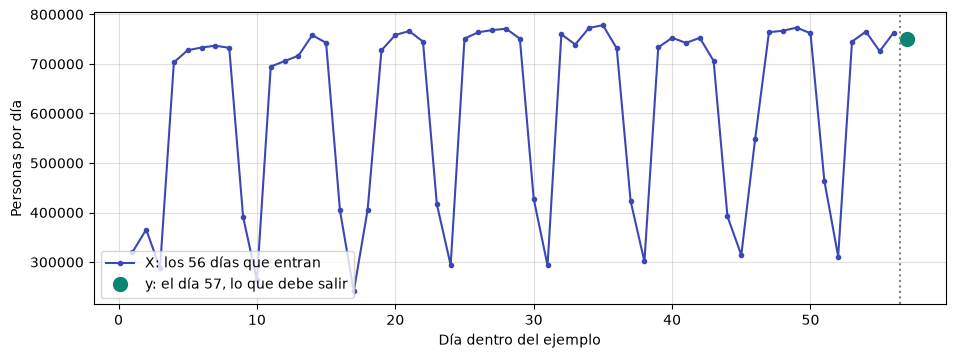

Forma de X: (56, 1)  Forma de y: (1,)


In [8]:
X, y = train_set_1[0]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(np.arange(1, 57), X[:, 0] * scale, "o-", color=INDIGO, ms=3, label="X: los 56 días que entran")
ax.plot(57, y * scale, "o", color=TEAL, ms=10, label="y: el día 57, lo que debe salir")
ax.axvline(56.5, color="gray", ls=":")
ax.set_xlabel("Día dentro del ejemplo"); ax.set_ylabel("Personas por día"); ax.grid(alpha=0.4); ax.legend(loc="lower left")
plt.show()
print("Forma de X:", tuple(X.shape), " Forma de y:", tuple(y.shape))

Las formas: X es `(56, 1)` porque son 56 pasos y en cada paso entra **1 número** (los pasajeros de ese día). y es `(1,)`: un solo número. Al juntar ejemplos en minibatches de 32, X pasa a ser `(32, 56, 1)` e y `(32, 1)`.

### La red

La red tiene dos capas:

- `self.gru`: la GRU que lee la serie. `nn.GRU` recibe X con forma `(batch, 56, 1)` y devuelve dos cosas: `outputs`, con el estado de **cada** paso, $h_1, \dots, h_{56}$ (forma `(batch, 56, 32)`), y `h_n`, el último estado.
- `self.head`: la capa densa `nn.Linear(32, 1)`, que convierte los 32 números del último estado en el pronóstico.

En `forward`, `outputs[:, -1]` toma el estado del **último** paso, $h_{56}$ (forma `(batch, 32)`), y lo pasa por la capa densa: sale `(batch, 1)`. Los estados de los pasos 1 a 55 se calculan, pero no se usan: son las flechas grises del esquema.

El argumento `target` no se usa en esta red. Está para que las cuatro redes del notebook se llamen igual desde la clase `Forecaster` (solo las redes con decodificador, en las etapas 6 y 7, lo necesitan).

In [9]:
class SeqToVector(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)   # estado (32) → un número

    def forward(self, X, target=None):
        outputs, h_n = self.gru(X)          # outputs: (batch, 56, 32), los estados h_1 ... h_56
        return self.head(outputs[:, -1])    # solo h_56 → (batch, 1)


torch.manual_seed(42)
seq_to_vector = Forecaster(SeqToVector())
seq_to_vector.fit(train_set_1, valid_set_1, epochs=100)

Entrenamiento: 100%|██████████| 100/100 [00:04<00:00, 22.71época/s, mae=38,866, mejor_val_mae=41,923, val_mae=44,097]

Mejor MAE de validación: 41,923 personas


La barra muestra el avance del entrenamiento: `mae` es el error medio en entrenamiento y `val_mae` en validación, en personas por día. Al final, `Forecaster` se queda con los pesos de la época con el menor error de validación.

### El pronóstico

Ahora le pedimos a la red un pronóstico para los ejemplos de **test**, un periodo de 2019 que nunca vio al entrenar. Se arman igual que los de entrenamiento: 56 días y, como etiqueta, el día siguiente (`horizon=1`).

En la gráfica de un ejemplo:

- **Índigo:** los 56 días que entran a la red (el día 0 es el último día conocido).
- **Verde:** lo que de verdad pasó al día siguiente.
- **Rojo:** lo que pronosticó la red para ese día: un solo número.

Forma del pronóstico para todo test: (214, 1) (ejemplos de test, 1 día)


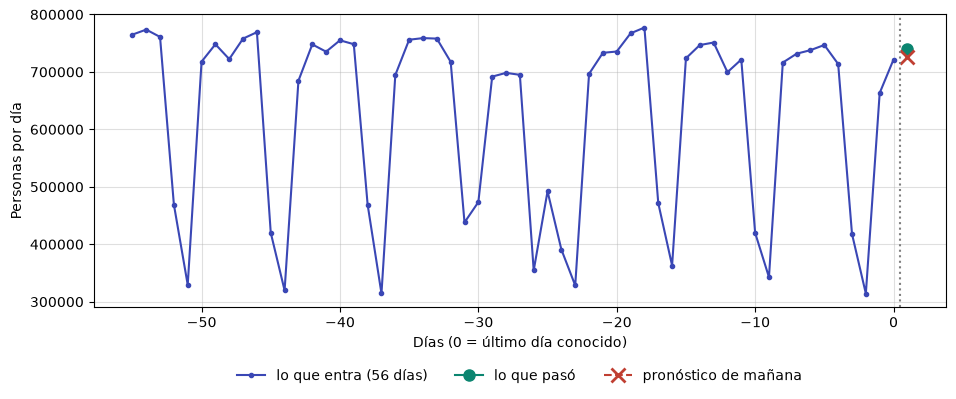

In [10]:
test_set_1 = WindowDataset(rail_test, horizon=1)
X_test_1, Y_test_1 = stack(test_set_1)   # X_test_1: (ejemplos, 56, 1); Y_test_1: (ejemplos, 1)
example = 60   # un ejemplo cualquiera de test (prueben con otros)

def plot_forecast(X, Y_true, Y_pred, label, i=example):
    # X: lo que entra; Y_true: lo que pasó; Y_pred: el pronóstico (1 o 14 días)
    past, future = np.arange(-window_length + 1, 1), np.arange(1, Y_true.shape[1] + 1)
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.plot(past, X[i, :, 0] * scale, ".-", color=INDIGO, label="lo que entra (56 días)")
    ax.plot(future, Y_true[i] * scale, "o-", color=TEAL, ms=8, label="lo que pasó")
    ax.plot(future, Y_pred[i] * scale, "x--", color=CORAL, ms=10, mew=2, label=label)
    ax.axvline(0.5, color="gray", ls=":")
    ax.set_xlabel("Días (0 = último día conocido)"); ax.set_ylabel("Personas por día")
    ax.grid(alpha=0.4); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False)
    plt.show()

Y_tomorrow_1 = seq_to_vector.predict(X_test_1)
print("Forma del pronóstico para todo test:", tuple(Y_tomorrow_1.shape), "(ejemplos de test, 1 día)")
plot_forecast(X_test_1, Y_test_1, Y_tomorrow_1, "pronóstico de mañana")

La red aprendió el patrón semanal: sabe en qué día de la semana termina la ventana y, por lo tanto, si mañana es un día alto (laboral) o bajo (fin de semana). Para medir qué tan bien lo hace en todo test lo comparamos con el **pronóstico ingenuo**: mañana será igual que el mismo día de la semana pasada. Una red que no le gane al ingenuo no vale la pena.

In [11]:
Y_naive_tomorrow = X_test_1[:, -7]   # el mismo día de la semana pasada: (ejemplos, 1)
mae = lambda Y_pred, Y_true: ((Y_pred - Y_true).abs().mean() * scale).item()
print(f"MAE de test, mañana, secuencia → vector: {mae(Y_tomorrow_1, Y_test_1):,.0f} personas")
print(f"MAE de test, mañana, ingenuo:            {mae(Y_naive_tomorrow, Y_test_1):,.0f} personas")

MAE de test, mañana, secuencia → vector: 37,424 personas
MAE de test, mañana, ingenuo:            62,949 personas


## Etapa 4: Arquitectura 2, secuencia → secuencia

### La idea

**Qué entra:** la misma secuencia, $X = (x_1, \dots, x_{56})$.

**Qué sale:** otra secuencia, del mismo largo: **una predicción en cada paso** de la lectura, $\hat y_1, \hat y_2, \dots, \hat y_{56}$. Después de leer $x_1$, la red ya entrega $\hat y_1$; después de leer $x_2$, entrega $\hat y_2$; y así hasta el final.

¿Qué predice en cada paso? **El día siguiente**: $\hat y_t$ es el pronóstico de $x_{t+1}$, hecho solo con lo leído hasta el paso $t$. Por ejemplo, $\hat y_1$ intenta adivinar el día 2 habiendo visto solo el día 1, y $\hat y_{56}$ intenta adivinar el día 57 habiendo visto los 56 días.

### ¿Qué cambia frente a secuencia → vector?

| | Arquitectura 1: secuencia → vector | Arquitectura 2: secuencia → secuencia |
|---|---|---|
| Qué entra | los 56 días | los 56 días (igual) |
| Cuándo sale una predicción | **solo al final**, después del paso 56 | **en cada paso**, del 1 al 56 |
| Cuántas predicciones salen | 1 | 56 |
| Qué se usa de la GRU | solo el último estado, $h_{56}$ | todos los estados, $h_1, \dots, h_{56}$ |
| Etiqueta | $y = x_{57}$ (un número) | $y = (x_2, \dots, x_{57})$ (56 números) |
| Errores de los que aprende por ejemplo | 1 | 56 |

La lectura es idéntica; cambia **qué se hace con lo leído**. La última predicción de secuencia → secuencia, $\hat y_{56}$, responde la misma pregunta que secuencia → vector: cuánta gente viajará mañana.

**En nuestro problema.** El mismo operador que pregunta cada noche por mañana. La diferencia está en **cómo se entrena** la red: en vez de aprender solo de su respuesta final, aprende de una respuesta en cada día de la ventana.

¿Por qué entrenar así? Porque la red **aprende de 56 errores por ejemplo** en vez de uno solo: en cada paso hay un pronóstico y una respuesta correcta con la que compararlo. Así tiene más señal de la que aprender en cada ejemplo. Además, sirve cuando los datos llegan uno a uno (pronóstico en tiempo real): cada vez que llega un dato nuevo, la red ya tiene listo el pronóstico del siguiente.

### El esquema

<img src="https://omarcastano.github.io/deeplearning-javeriana-site/modulo_2/unidad_2/3_experiencia/nueva/imagenes/arq2_secuencia_secuencia.png" alt="Secuencia → secuencia" width="620">

*Esquema de la presentación "Arquitecturas y práctica", con 6 pasos (en el notebook son 56).*

Comparado con el esquema de secuencia → vector, la parte de abajo es igual: la misma GRU lee $x_1, \dots, x_{56}$ y pasa su memoria (flechas naranjas) de un paso al siguiente. Lo que cambia es la parte de arriba: **ninguna salida se descarta** (ya no hay flechas grises). Cada estado $h_t$ pasa por la capa densa y da su predicción $\hat y_t$ (flechas verdes).

### Los ejemplos: quién es X y quién es y

X no cambia: 56 días seguidos. Lo que cambia es la etiqueta: ahora **y es la misma ventana corrida un día**, $y = (x_2, x_3, \dots, x_{57})$, porque en el paso $t$ la respuesta correcta es el día $t+1$:

| Paso | Lo que la red ya leyó | Lo que debe predecir |
|---|---|---|
| 1 | $x_1$ | $y_1 = x_2$ |
| 2 | $x_1, x_2$ | $y_2 = x_3$ |
| … | … | … |
| 56 | $x_1, \dots, x_{56}$ | $y_{56} = x_{57}$ |

En secuencia → vector la etiqueta era solo la última fila de esta tabla.

Para armar estos ejemplos escribimos `SeqToSeqDataset`, que hereda de `WindowDataset` y solo cambia la etiqueta. En la tabla, cada fila es un ejemplo; fíjense en que la columna `y_1` es igual a `x_2`, `y_2` es igual a `x_3`, y así.

In [12]:
class SeqToSeqDataset(WindowDataset):
    # Etiqueta = la ventana corrida un día: y_t = x_(t+1)
    def __len__(self):
        return len(self.values) - self.window_length

    def __getitem__(self, idx):
        end = idx + self.window_length
        X = self.values[idx:end].unsqueeze(-1)   # (56, 1): x_1 ... x_56
        y = self.values[idx + 1:end + 1]         # (56,):   x_2 ... x_57
        return X, y


train_set_2 = SeqToSeqDataset(rail_train)
valid_set_2 = SeqToSeqDataset(rail_valid)
windows_table(train_set_2)

,x_1,x_2,x_3,x_4,x_5,x_6,...,y_51,y_52,y_53,y_54,y_55,y_56
ejemplo 1,319835,365509,287661,703185,727716,733167,...,311190,745072,765309,725712,762858,749991
ejemplo 2,365509,287661,703185,727716,733167,736809,...,745072,765309,725712,762858,749991,455421
ejemplo 3,287661,703185,727716,733167,736809,732495,...,765309,725712,762858,749991,455421,323758
ejemplo 4,703185,727716,733167,736809,732495,391597,...,725712,762858,749991,455421,323758,742972
ejemplo 5,727716,733167,736809,732495,391597,263073,...,762858,749991,455421,323758,742972,741922


En la gráfica, los primeros 15 días del primer ejemplo (con los 56 no se alcanza a ver). Cada círculo verde $y_t$ queda **encima del punto índigo del día siguiente**, $x_{t+1}$: la etiqueta es la misma serie, un día adelantada. En el día 1 no hay círculo, porque ningún paso tiene que predecir $x_1$. En la gráfica de secuencia → vector había un solo punto verde, al final; aquí hay uno en cada día.

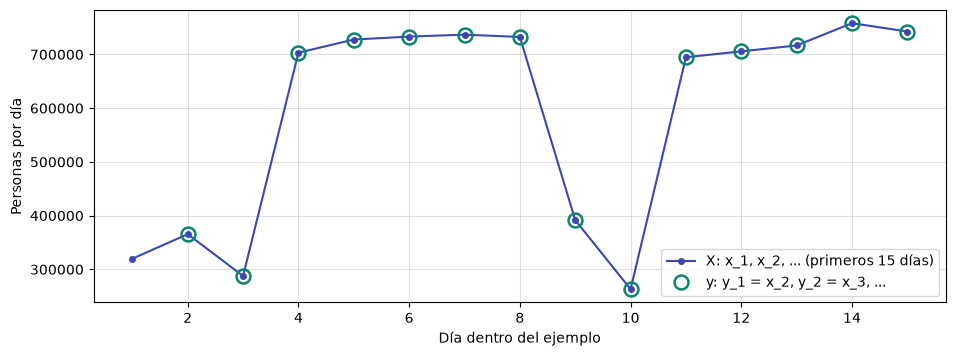

Forma de X: (56, 1)  Forma de y: (56,)


In [13]:
X, y = train_set_2[0]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(np.arange(1, 16), X[:15, 0] * scale, "o-", color=INDIGO, ms=4, label="X: x_1, x_2, ... (primeros 15 días)")
ax.plot(np.arange(2, 16), y[:14] * scale, "o", color=TEAL, ms=10, mfc="none", mew=1.8, label="y: y_1 = x_2, y_2 = x_3, ...")
ax.set_xlabel("Día dentro del ejemplo"); ax.set_ylabel("Personas por día"); ax.grid(alpha=0.4); ax.legend(loc="lower right")
plt.show()
print("Forma de X:", tuple(X.shape), " Forma de y:", tuple(y.shape))

Las formas: X sigue siendo `(56, 1)`, pero ahora y es `(56,)`: una respuesta correcta por cada paso (en secuencia → vector era `(1,)`).

### La red

La red es casi igual a `SeqToVector`. La **única** línea que cambia es la última de `forward`:

- En `SeqToVector`: `self.head(outputs[:, -1])`, la capa densa solo sobre el último estado.
- En `SeqToSeq`: `self.head(outputs)`, la capa densa sobre **todos** los estados.

`nn.Linear` trabaja sobre la última dimensión del tensor, así que con esa sola línea convierte cada uno de los 56 estados en su predicción, con los mismos pesos: de `(batch, 56, 32)` pasa a `(batch, 56, 1)`. Al final, `squeeze(-1)` quita la dimensión de tamaño 1 y quedan `(batch, 56)`, que es la forma de y.

In [14]:
class SeqToSeq(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)   # estado (32) → un número

    def forward(self, X, target=None):
        outputs, h_n = self.gru(X)              # (batch, 56, 32): h_1 ... h_56
        return self.head(outputs).squeeze(-1)   # una predicción por paso → (batch, 56)


torch.manual_seed(42)
seq_to_seq = Forecaster(SeqToSeq())
seq_to_seq.fit(train_set_2, valid_set_2, epochs=100)

Entrenamiento: 100%|██████████| 100/100 [00:04<00:00, 23.14época/s, mae=37,104, mejor_val_mae=57,332, val_mae=66,670]

Mejor MAE de validación: 57,332 personas


Aquí el error de la barra (`mae`, `val_mae`) es el promedio de los 56 pasos, incluidos los primeros, en los que la red ha leído muy poco. Por eso es más alto que el de secuencia → vector y no se puede comparar directamente con él.

### El pronóstico en cada paso

Para un ejemplo de test, la gráfica muestra lo que la red predice en **cada** paso (rojo) frente a lo que de verdad pasó al día siguiente (verde). En los primeros pasos la red ha leído uno o dos días y no sabe bien en qué parte de la semana está, así que se equivoca más. A medida que lee la ventana, sus predicciones se acercan a lo real.

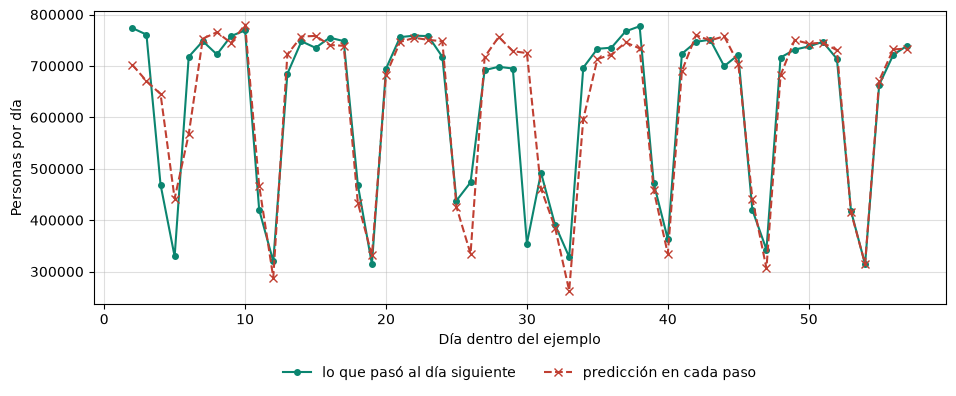

In [15]:
X, y = SeqToSeqDataset(rail_test)[example]
y_pred = seq_to_seq.predict(X.unsqueeze(0))[0]   # unsqueeze(0): un batch con un solo ejemplo
t = np.arange(2, window_length + 2)
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(t, y * scale, "o-", color=TEAL, ms=4, label="lo que pasó al día siguiente")
ax.plot(t, y_pred * scale, "x--", color=CORAL, label="predicción en cada paso")
ax.set_xlabel("Día dentro del ejemplo"); ax.set_ylabel("Personas por día"); ax.grid(alpha=0.4)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
plt.show()

### Comparación con secuencia → vector

La predicción del **último paso**, $\hat y_{56}$, es el pronóstico de mañana, igual que el de secuencia → vector. Así que podemos comparar las dos arquitecturas en la misma pregunta. `[:, -1:]` toma la última de las 56 predicciones de cada ejemplo:

In [16]:
Y_tomorrow_2 = seq_to_seq.predict(X_test_1)[:, -1:]   # solo la predicción del paso 56: (ejemplos, 1)
print(f"MAE de test, mañana, secuencia → vector:    {mae(Y_tomorrow_1, Y_test_1):,.0f} personas")
print(f"MAE de test, mañana, secuencia → secuencia: {mae(Y_tomorrow_2, Y_test_1):,.0f} personas")
print(f"MAE de test, mañana, ingenuo:               {mae(Y_naive_tomorrow, Y_test_1):,.0f} personas")

MAE de test, mañana, secuencia → vector:    37,424 personas
MAE de test, mañana, secuencia → secuencia: 37,259 personas
MAE de test, mañana, ingenuo:               62,949 personas


Las dos le ganan al ingenuo y quedan parecidas (los números cambian un poco en cada ejecución). Es lo esperado: leen lo mismo y responden lo mismo en el último paso; la diferencia está en cómo se entrenaron. En series más difíciles, aprender de un error en cada paso suele ayudar a que la red aprenda más rápido.

Hasta aquí las dos arquitecturas responden **mañana**. Pero la CTA necesita **14 días**. Las siguientes etapas muestran cómo llegar a ellos.

## Etapa 5: De un día a catorce: pronosticar paso a paso (autorregresivo)

### La idea

Para armar los turnos, la CTA necesita **un pronóstico para cada uno de los próximos 14 días**. En esta etapa **obtenemos esos 14 días**.

El punto de partida es la red de secuencia → vector de la etapa 3, que cada vez que se usa entrega **un solo día**: el siguiente a la ventana que lee. Para llegar a 14 días **no entrenamos una red nueva**: usamos esa misma red **14 veces seguidas**. Cada vez que da un día, ese pronóstico se agrega al final de la ventana como si fuera un dato real, y la red se vuelve a usar para dar el día siguiente. Al terminar las 14 vueltas tenemos los 14 días.

A esto se le llama pronosticar **paso a paso** o de forma **autorregresiva**: la red usa sus propias predicciones como si fueran datos.

### ¿Qué cambia frente a las etapas 3 y 4?

| | Etapas 3 y 4 | Etapa 5: paso a paso |
|---|---|---|
| Red | secuencia → vector (o secuencia → secuencia) | **la misma** red de la etapa 3, sin volver a entrenar |
| Cuántos días se obtienen | 1 (mañana) | **14** (uno en cada uso de la red) |
| Cuántas veces se usa la red | 1 vez | **14 veces seguidas** |
| Qué lee la red | los 56 días reales | al principio los 56 reales; después, cada vez más pronósticos suyos |

### Cómo funciona

<img src="https://omarcastano.github.io/deeplearning-javeriana-site/modulo_2/unidad_2/3_experiencia/nueva/imagenes/paso_a_paso.png" alt="Pronóstico paso a paso" width="620">

*Esquema de la presentación, con 5 valores que entran y 3 pasos (en el notebook son 56 valores y 14 pasos). Índigo: datos reales. Verde: pronósticos.*

Repetimos 14 veces:

1. La red lee la ventana actual de 56 días y pronostica el día siguiente.
2. Corremos la ventana un día: quitamos el día más viejo y agregamos **el pronóstico** al final, como si fuera un dato real.

Así cambia la ventana que entra a la red en cada uno de los 14 usos (índigo = datos reales, verde = pronósticos en el esquema):

| Uso de la red | Ventana de 56 días que entra | Sale |
|---|---|---|
| 1 | $x_1, x_2, \dots, x_{56}$ (56 reales) | $\hat x_{57}$ |
| 2 | $x_2, \dots, x_{56}, \hat x_{57}$ (55 reales y 1 pronóstico) | $\hat x_{58}$ |
| 3 | $x_3, \dots, x_{56}, \hat x_{57}, \hat x_{58}$ (54 reales y 2 pronósticos) | $\hat x_{59}$ |
| … | … | … |
| 14 | $x_{14}, \dots, x_{56}, \hat x_{57}, \dots, \hat x_{69}$ (43 reales y 13 pronósticos) | $\hat x_{70}$ |

Fíjense en lo que pasa: el pronóstico del día 14 se hace con una ventana en la que **13 de los 56 valores son pronósticos**, no datos reales. Si $\hat x_{57}$ tiene un error, ese error entra en el cálculo de $\hat x_{58}$, y ambos en el de $\hat x_{59}$: los errores **se pueden acumular**. Además, la red nunca practicó con ventanas que tuvieran pronósticos adentro: al entrenar siempre leyó datos reales.

### El código

Para medir los 14 días, ahora sí necesitamos ejemplos de test cuya etiqueta sean **los 14 días siguientes** a cada ventana: los armamos con `WindowDataset(rail_test, horizon=14)`. X sigue siendo `(56, 1)` por ejemplo; la etiqueta pasa de `(1,)` a `(14,)`. Estos mismos ejemplos de test se usan en las etapas 6, 7 y 8, así que las tres formas de pronosticar 14 días se comparan sobre los mismos datos.

`forecast_step_by_step` hace el ciclo para todas las ventanas de test a la vez:

- `forecaster.predict(X)` devuelve el pronóstico de mañana de cada ventana, forma `(batch, 1)`. (Con `[:, -1:]` se toma la última columna; así la misma función sirve también para la red de secuencia → secuencia, que devuelve 56 columnas.)
- `X[:, 1:]` quita el día más viejo de cada ventana (quedan 55) y `torch.cat` pega el pronóstico al final (vuelven a ser 56). `unsqueeze(-1)` le da al pronóstico la forma `(batch, 1, 1)` que necesita para pegarse a X, que es `(batch, 55, 1)`.

Forma del pronóstico para todo test: (201, 14) (ejemplos de test, 14 días)


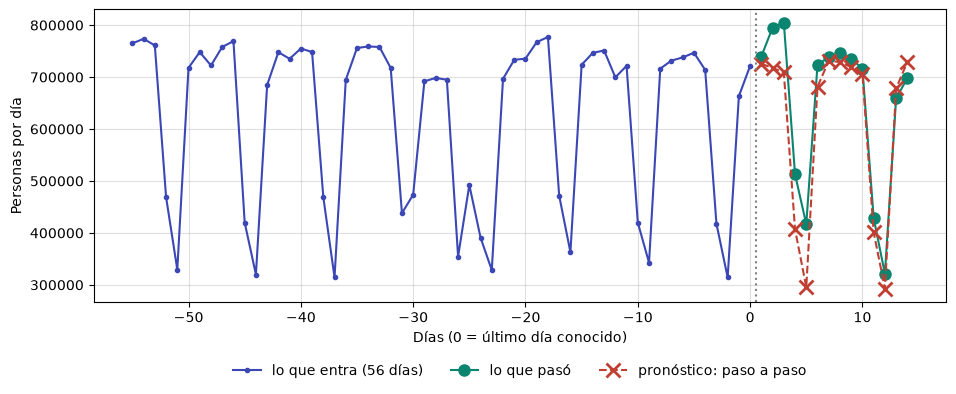

In [17]:
def forecast_step_by_step(forecaster, X, horizon=14):
    # X: (batch, 56, 1). Devuelve (batch, horizon)
    predictions = []
    for _ in range(horizon):
        y_next = forecaster.predict(X)[:, -1:]                   # el pronóstico del día siguiente: (batch, 1)
        predictions.append(y_next)
        X = torch.cat([X[:, 1:], y_next.unsqueeze(-1)], dim=1)  # corre la ventana un día
    return torch.cat(predictions, dim=1)


test_set = WindowDataset(rail_test, horizon=14)
X_test, Y_test = stack(test_set)   # X_test: (ejemplos, 56, 1); Y_test: (ejemplos, 14)

Y_step_by_step = forecast_step_by_step(seq_to_vector, X_test)
print("Forma del pronóstico para todo test:", tuple(Y_step_by_step.shape), "(ejemplos de test, 14 días)")
plot_forecast(X_test, Y_test, Y_step_by_step, "pronóstico: paso a paso")

Es el mismo ejemplo de test de la etapa 3: el primer punto rojo es el mismo pronóstico de mañana de allá, y los otros 13 salen de usar la red otra vez con sus propios pronósticos. Ahora en verde se ven los 14 días que de verdad pasaron. En esta serie, que tiene un patrón semanal muy regular, los errores casi no se acumulan: la red de un día es buena, y sus pronósticos se parecen tanto a datos reales que no la desvían. En series más irregulares la forma paso a paso suele alejarse más a medida que avanza el horizonte.

Las dos arquitecturas que siguen son distintas: son redes **hechas para entregar una secuencia**, que se entrenan desde el principio para generar los 14 días.

## Etapa 6: Arquitectura 3, vector → secuencia

### La idea

**Qué entra:** un solo vector, con unos pocos números que describen la situación. **No hay una serie que leer.**

**Qué sale:** una secuencia, los 14 días, que la red **genera un día a la vez**: $\hat y_1, \hat y_2, \dots, \hat y_{14}$.

**En nuestro problema.** Las arquitecturas anteriores necesitan los 56 días de historia. Pero muchas veces no se tiene la historia completa, o no hace falta tanta: para planear basta con **describir la situación** con unos pocos números. Por ejemplo: "las dos semanas empiezan un lunes, estamos en marzo y la semana pasada viajaron en promedio 650 000 personas por día". Con esa descripción, alguien con experiencia ya podría dibujar más o menos las dos semanas: cinco días altos, un sábado más bajo, un domingo aún más bajo, y otra vez lo mismo. Eso es lo que aprende esta red.

¿Qué números describen las próximas dos semanas del metro? Usamos **nueve**:

- **Día de la semana** en que empieza el pronóstico, con 7 números (`lun` a `dom`): un 1 en el día que corresponde y 0 en los demás. Por ejemplo, si empieza un miércoles: `0 0 1 0 0 0 0`. Así se le dice a la red dónde arranca el patrón semanal.
- **Mes**, dividido entre 12 (enero = 0.08, …, diciembre = 1). Le dice a la red en qué época del año estamos.
- **Promedio de la última semana**, dividido entre un millón. Le dice a la red cuánta gente está viajando últimamente (el nivel).

**¿Por qué los 14 días salen uno por uno y no juntos?** Porque cada día depende del anterior: si el día 5 fue un viernes alto, el día 6 es un sábado bajo. La red genera un día, lo usa como entrada para generar el siguiente, y así.

### ¿Qué cambia frente a las arquitecturas anteriores y a la etapa 5?

| | Arquitecturas 1 y 2 | Etapa 5: paso a paso | Arquitectura 3: vector → secuencia |
|---|---|---|---|
| Qué entra | 56 días | 56 días | **9 números** |
| Qué sale | mañana | 14 días | 14 días |
| Quién hace el ciclo de 14 pasos | no hay ciclo | **nosotros**, por fuera de la red | **la red**, por dentro |
| Qué aprendió la red al entrenar | a dar un día | a dar un día (es la red de la etapa 3) | a **generar los 14 días** |
| Contra qué se compara al entrenar | 1 día (o 1 día en cada paso) | (no se entrena) | los 14 días |

La etapa 5 y esta arquitectura se parecen en algo: las dos usan pronósticos como entrada del paso siguiente. La diferencia es que en la etapa 5 usamos una red que solo había aprendido a dar un día, y el ciclo lo programamos nosotros; aquí el ciclo es **parte de la red** y la red se entrena para hacerlo bien en los 14 pasos.

### El esquema

<img src="https://omarcastano.github.io/deeplearning-javeriana-site/modulo_2/unidad_2/3_experiencia/nueva/imagenes/arq3_vector_secuencia.png" alt="Vector → secuencia" width="620">

*Esquema de la presentación "Arquitecturas y práctica", con 6 pasos (en el notebook son 14).*

Cómo leer el esquema, comparándolo con los anteriores:

- **Abajo ya no hay una serie:** el vector entra **solo en el paso 1** (flecha índigo). Es lo único que la red sabe de la situación.
- **Cada caja es el mismo paso de una GRU.** A esta parte de la red, que genera una serie paso a paso, se le llama **decodificador**.
- **Arriba sale una predicción en cada paso** $\hat y_t$ (flechas verdes), como en secuencia → secuencia.
- **Las flechas verdes punteadas** son lo nuevo: cada predicción **vuelve a entrar** como dato en el paso siguiente.
- **Las flechas naranjas** son la memoria que pasa de un paso al siguiente, como siempre.

### ¿Qué entra y qué sale en cada paso?

Esta es la parte más distinta frente a las arquitecturas anteriores, así que la vemos con calma:

- **Antes del paso 1:** el vector de 9 números pasa por una capa densa que lo convierte en la **memoria inicial** del decodificador (32 números). En las arquitecturas 1 y 2 la memoria empezaba en cero; aquí empieza con la descripción de la situación.
- **Paso 1:** todavía no hay ningún día anterior, así que entra un **cero**. Sale $\hat y_1$, el primer día del pronóstico.
- **Pasos 2 a 14:** entra **el día anterior** y sale el día siguiente: en el paso 2 entra $\hat y_1$ y sale $\hat y_2$; en el paso 3 entra $\hat y_2$ y sale $\hat y_3$; y así.

En las arquitecturas 1 y 2, en cada paso entraba un dato real de la serie ($x_t$). Aquí no hay serie que leer: lo que entra en cada paso es lo que la red acaba de pronosticar.

### Teacher forcing: cómo se entrena

Al **entrenar** hay un detalle importante. Si en cada paso le diéramos a la red su propio pronóstico, al principio del entrenamiento (cuando sus pronósticos todavía son malos) cada paso recibiría basura del anterior, y aprender sería lento y difícil.

Por eso, al entrenar se usa **teacher forcing** ("forzar con el profesor"), que vimos en la presentación: en cada paso, en vez de su pronóstico, la red recibe el **valor real** del día anterior, que conocemos porque está en la etiqueta:

Un ejemplo: si el día 3 fue un domingo con 320 000 personas y la red pronosticó 500 000, al entrenar el paso 4 recibe 320 000 (lo real) y no 500 000. Así cada paso aprende "dado el día anterior, ¿cómo es el siguiente?" sin que el error de un paso arruine los demás. Al pronosticar de verdad no conocemos los valores reales, y la red usa los suyos.

Así la red se entrena para acertar en los **14 días**, no solo en el primero: esa es la gran diferencia con la etapa 5, donde la red solo se había entrenado para dar un día.

### Los ejemplos: quién es X y quién es y

`VectorDataset` arma los mismos ejemplos que `WindowDataset` con `horizon=14` (los mismos 14 días como etiqueta), pero en vez de dar a la red los 56 días le da el vector de 9 números calculado a partir de ellos:

- `first_day` es la fecha del primer día que se pronostica; de ella salen el día de la semana y el mes.
- `last_week` es el promedio de los últimos 7 días de la ventana.

En la tabla, cada fila es un ejemplo: **las nueve primeras columnas forman el vector X** y las columnas `y_1` a `y_14` forman y. Frente a las tablas anteriores, X ya no tiene columnas `x_1 … x_56`: no hay serie, solo la descripción. Fíjense en que de una fila a la siguiente el 1 de los días de la semana se corre una columna: cada ejemplo empieza un día después.

In [18]:
class VectorDataset(WindowDataset):
    # Los mismos ejemplos de WindowDataset, pero X es un vector de 9 números en vez de 56 días
    def __getitem__(self, idx):
        end = idx + self.window_length
        first_day = self.dates[end]                             # primer día que se pronostica
        weekday = torch.zeros(7)
        weekday[first_day.day_of_week] = 1.0                    # lun = 0, ..., dom = 6
        month = torch.tensor([first_day.month / 12])
        last_week = self.values[end - 7:end].mean().reshape(1)
        v = torch.cat([weekday, month, last_week])              # (9,)
        y = self.values[end:end + self.horizon]                 # (14,), igual que en WindowDataset
        return v, y


train_set_3 = VectorDataset(rail_train, horizon=14)
valid_set_3 = VectorDataset(rail_valid, horizon=14)
test_set_3 = VectorDataset(rail_test, horizon=14)

columns = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom", "mes", "promedio_semana"]
y_columns = [f"y_{h + 1}" for h in range(horizon)]
rows = [torch.cat(train_set_3[i]).numpy() for i in range(5)]
table = pd.DataFrame(rows, columns=columns + y_columns, index=[f"ejemplo {i + 1}" for i in range(5)])
table[columns[:7]] = table[columns[:7]].astype(int)
table[y_columns] = (table[y_columns] * scale).round().astype(int)
with pd.option_context("display.max_columns", 16):
    display(table.round(2))

,lun,mar,mié,jue,vie,sáb,dom,mes,...,y_7,y_8,y_9,y_10,y_11,y_12,y_13,y_14
ejemplo 1,0,0,0,0,1,0,0,0.17,...,764033,754750,421193,327173,739174,781301,768961,780687
ejemplo 2,0,0,0,0,0,1,0,0.17,...,754750,421193,327173,739174,781301,768961,780687,797977
ejemplo 3,0,0,0,0,0,0,1,0.17,...,421193,327173,739174,781301,768961,780687,797977,605182
ejemplo 4,1,0,0,0,0,0,0,0.17,...,327173,739174,781301,768961,780687,797977,605182,303129
ejemplo 5,0,1,0,0,0,0,0,0.25,...,739174,781301,768961,780687,797977,605182,303129,766595


En la gráfica, el primer ejemplo: a la izquierda, el vector que entra (un 1 en el día en que empieza el pronóstico, el mes y el promedio de la semana); a la derecha, los 14 días que la red debe generar a partir de él. Comparen: si el vector dice que el pronóstico empieza un viernes, la serie de la derecha empieza con un día alto, luego un sábado y un domingo bajos, y después cinco días altos.

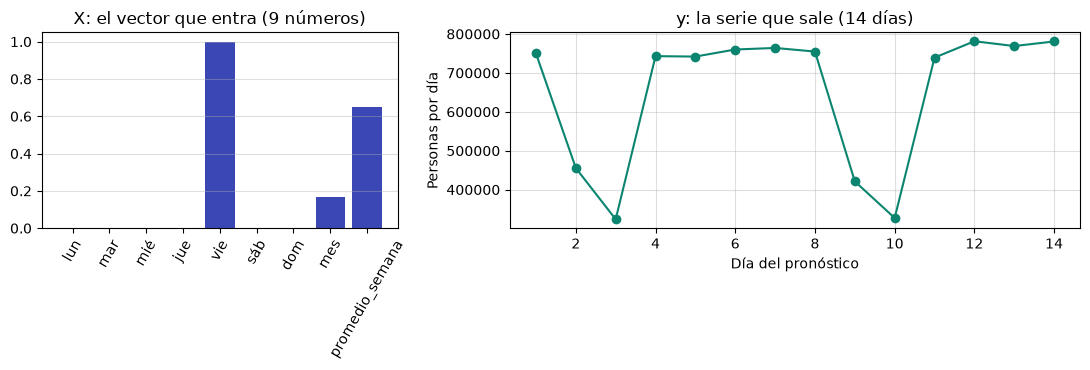

Forma de X: (9,)  Forma de y: (14,)


In [19]:
v, y = train_set_3[0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.6]})
ax1.bar(columns, v, color=INDIGO)
ax1.set_title("X: el vector que entra (9 números)"); ax1.tick_params(axis="x", rotation=60); ax1.grid(alpha=0.4, axis="y")
ax2.plot(np.arange(1, horizon + 1), y * scale, "o-", color=TEAL)
ax2.set_title("y: la serie que sale (14 días)"); ax2.set_xlabel("Día del pronóstico"); ax2.set_ylabel("Personas por día")
ax2.grid(alpha=0.4)
plt.tight_layout(); plt.show()
print("Forma de X:", tuple(v.shape), " Forma de y:", tuple(y.shape))

Las formas: X es `(9,)`, un vector, no una serie (no tiene dimensión de pasos, a diferencia de `(56, 1)`). y es `(14,)`: los 14 días.

### La red

La escribimos en dos clases, porque el decodificador lo vuelve a usar la arquitectura 4.

**`Decoder`** genera los 14 días. Usa `nn.GRUCell`, que es **un solo paso** de una GRU: recibe la entrada de ese paso, forma `(batch, 1)`, y el estado anterior, forma `(batch, 32)`, y devuelve el estado nuevo.

¿Por qué no `nn.GRU`, como en las arquitecturas 1 y 2? Porque `nn.GRU` recorre toda la serie de una vez, y para eso necesita tener todas las entradas desde el principio. Aquí no las tenemos: la entrada de cada paso (el pronóstico anterior) **no existe hasta que se calcula el paso anterior**. Por eso el decodificador recorre los 14 pasos con un `for`. En cada vuelta:

1. `self.cell(y_prev, h)`: un paso de la GRU, que actualiza la memoria con la entrada de ese paso.
2. `self.head(h)`: la capa densa, que convierte la memoria en el pronóstico de ese día.
3. Elige la entrada del paso siguiente: si recibió `target` (al entrenar), el valor real del día (*teacher forcing*); si no (al pronosticar), su propio pronóstico.

`Forecaster` pasa `target` en `train_epoch` y no lo pasa en `evaluate` ni en `predict`. Por eso la red usa *teacher forcing* solo al entrenar.

**`VectorToSeq`** arma la arquitectura completa: la capa densa `to_state` convierte el vector en la memoria inicial y el decodificador genera los 14 días, empezando con un cero como primera entrada.

In [20]:
class Decoder(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.cell = nn.GRUCell(input_size=1, hidden_size=hidden_size)   # un paso de una GRU
        self.head = nn.Linear(hidden_size, 1)                           # estado (32) → un número

    def forward(self, h, first_input, horizon=14, target=None):
        # h: memoria inicial (batch, 32); first_input: lo que entra en el paso 1 (batch, 1)
        y_prev, predictions = first_input, []
        for t in range(horizon):
            h = self.cell(y_prev, h)            # un paso de la GRU: memoria nueva
            y_t = self.head(h)                  # pronóstico de este día: (batch, 1)
            predictions.append(y_t)
            if target is not None:              # al entrenar: el valor real (teacher forcing)
                y_prev = target[:, t:t + 1]
            else:                               # al pronosticar: su propio pronóstico
                y_prev = y_t
        return torch.cat(predictions, dim=1)    # (batch, 14)


class VectorToSeq(nn.Module):
    def __init__(self, n_features=9, hidden_size=32, horizon=14):
        super().__init__()
        self.to_state = nn.Linear(n_features, hidden_size)   # vector de 9 números → memoria de 32
        self.decoder = Decoder(hidden_size)
        self.horizon = horizon

    def forward(self, v, target=None):
        h0 = torch.tanh(self.to_state(v))                     # memoria inicial: (batch, 32)
        first_input = torch.zeros(len(v), 1, device=v.device) # en el paso 1 entra un cero
        return self.decoder(h0, first_input, self.horizon, target)


torch.manual_seed(42)
vector_to_seq = Forecaster(VectorToSeq())
vector_to_seq.fit(train_set_3, valid_set_3, epochs=100)

Entrenamiento: 100%|██████████| 100/100 [00:13<00:00,  7.51época/s, mae=36,980, mejor_val_mae=40,883, val_mae=59,212]

Mejor MAE de validación: 40,883 personas


El entrenamiento tarda más que en las etapas anteriores porque el `for` del decodificador recorre los 14 pasos uno por uno en cada minibatch. Aquí `mae` y `val_mae` son el promedio de los 14 días.

### El pronóstico

El mismo ejemplo de test de las etapas anteriores. **Ojo:** esta red **no vio** los 56 días en índigo; se dibujan solo como referencia. Lo único que recibió fueron los nueve números del vector (día de la semana, mes y promedio de la última semana).

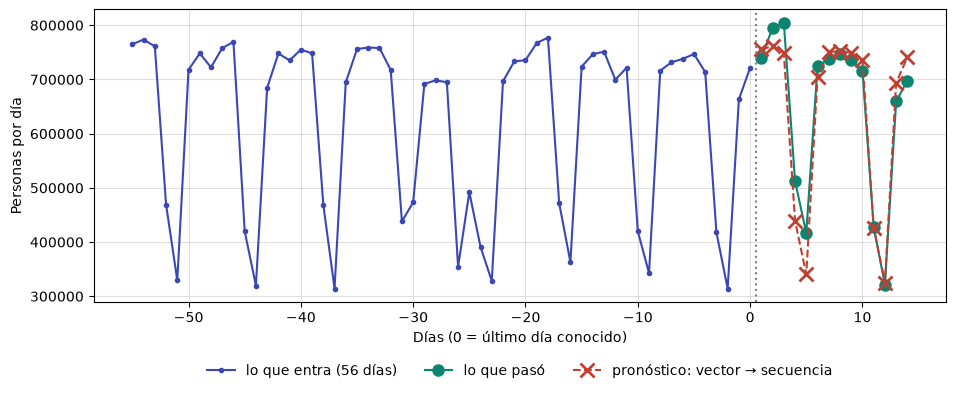

In [21]:
V_test, Y_test_3 = stack(test_set_3)
assert torch.equal(Y_test_3, Y_test)   # los mismos 14 días que en las otras arquitecturas
Y_vector_to_seq = vector_to_seq.predict(V_test)
plot_forecast(X_test, Y_test, Y_vector_to_seq, "pronóstico: vector → secuencia")

Con solo nueve números, la red genera una serie con la forma correcta: cinco días altos y dos bajos, en el orden que indica el día de la semana, y al nivel que indica el promedio de la última semana. Lo que no puede saber es lo que pasó ayer ni los detalles de las últimas semanas; por eso, como veremos en la etapa 8, se equivoca un poco más que las redes que leen la serie.

## Etapa 7: Arquitectura 4, codificador–decodificador

### La idea

**Qué entra:** una secuencia, los últimos 56 días: $X = (x_1, \dots, x_{56})$.

**Qué sale:** otra secuencia, los 14 días siguientes, generados uno por uno: $\hat y_1, \dots, \hat y_{14}$. La secuencia que sale tiene **otro largo** que la que entra (14 frente a 56), y eso no es problema.

**En nuestro problema.** Es otra vez la pregunta de la CTA (los próximos 14 días), pero ahora la red sí lee los últimos 56 días. Junta las dos ideas que ya vimos:

- Como en **secuencia → vector** (etapa 3), una GRU **lee toda la historia** y la resume en su último estado. A esta parte se le llama **codificador**, y a su último estado, **contexto**.
- Como en **vector → secuencia** (etapa 6), un **decodificador** genera los 14 días uno por uno.

### ¿Qué cambia frente a las arquitecturas anteriores?

| | Secuencia → vector (etapa 3) | Vector → secuencia (etapa 6) | Codificador–decodificador |
|---|---|---|---|
| Qué entra | 56 días | 9 números | 56 días |
| Qué sale | mañana | 14 días, uno por uno | 14 días, uno por uno |
| De dónde sale la memoria inicial del decodificador | (no hay decodificador) | de los 9 números, con una capa densa | del **contexto**: el resumen que hace el codificador al leer los 56 días |
| Primera entrada del decodificador | (no hay decodificador) | un 0 | el último día conocido, $x_{56}$ |

Dicho de otra forma: el codificador–decodificador es **vector → secuencia donde el vector ya no lo escogemos nosotros** (día de la semana, mes, promedio), sino que **lo aprende la red** leyendo la historia. Y frente a la etapa 5 (paso a paso), aquí la red se entrena para generar los 14 días, no solo el primero.

### El esquema

<img src="https://omarcastano.github.io/deeplearning-javeriana-site/modulo_2/unidad_2/3_experiencia/nueva/imagenes/arq4_codificador_decodificador.png" alt="Codificador–decodificador" width="620">

*Esquema de la presentación "Arquitecturas y práctica", con 4 valores que entran y 3 que salen (en el notebook son 56 y 14).*

Cómo leer el esquema:

- **A la izquierda, el codificador** ("cod."): es el esquema de secuencia → vector. La misma GRU lee $x_1, \dots, x_{56}$, uno por paso, y sus salidas intermedias no se usan (flechas grises).
- **En el centro, el contexto:** el último estado del codificador. Ocupa el lugar que en secuencia → vector tenía la capa densa: en vez de convertirse en un pronóstico, se le entrega al decodificador. Es lo único que pasa de un lado al otro; el decodificador **no ve** la serie de entrada, solo este resumen.
- **A la derecha, el decodificador** ("dec."): es el esquema de vector → secuencia, pero con el contexto en lugar del vector. Genera $\hat y_1, \hat y_2, \dots$ y cada predicción vuelve a entrar en el paso siguiente (flechas verdes punteadas).

### ¿Qué entra y qué sale en cada paso?

- **Pasos 1 a 56 (codificador):** en cada paso entra un día real, $x_1, \dots, x_{56}$, como en secuencia → vector. No sale ningún pronóstico: solo se va actualizando la memoria.
- **El contexto:** la memoria al terminar el paso 56 (32 números). Es la memoria inicial del decodificador; en vector → secuencia esa memoria salía de los 9 números.
- **Paso 1 del decodificador:** entra el **último día conocido**, $x_{56}$ (en vector → secuencia entraba un cero, porque no había día anterior). Sale $\hat y_1$.
- **Pasos 2 a 14 del decodificador:** como en vector → secuencia, entra el día anterior y sale el siguiente: el valor real al entrenar (*teacher forcing*) y su propio pronóstico al pronosticar.

### Los ejemplos: quién es X y quién es y

Lo que entra es lo mismo que en secuencia → vector (56 días) y lo que debe salir es lo mismo que en vector → secuencia (14 días). Por eso usamos `WindowDataset` con `horizon=14`:

- **X** son 56 días seguidos: $X = (x_1, \dots, x_{56})$. Los lee el codificador.
- **y** son los 14 días siguientes: $y = (y_1, \dots, y_{14})$, donde $y_1$ es el día 57 de la ventana y $y_{14}$ el día 70. Los genera el decodificador, uno por uno. Al entrenar, además, el decodificador recibe $y_1, \dots, y_{13}$ como entradas (*teacher forcing*).

En la tabla, cada fila es un ejemplo: las columnas `x_1` a `x_56` forman X y las columnas `y_1` a `y_14` forman y. Frente a la tabla de secuencia → vector, X es igual, pero ahora hay 14 columnas de y en vez de una.

In [22]:
train_set_4 = WindowDataset(rail_train, horizon=14)
valid_set_4 = WindowDataset(rail_valid, horizon=14)
windows_table(train_set_4)

,x_1,x_2,x_3,x_4,x_5,x_6,...,y_9,y_10,y_11,y_12,y_13,y_14
ejemplo 1,319835,365509,287661,703185,727716,733167,...,421193,327173,739174,781301,768961,780687
ejemplo 2,365509,287661,703185,727716,733167,736809,...,327173,739174,781301,768961,780687,797977
ejemplo 3,287661,703185,727716,733167,736809,732495,...,739174,781301,768961,780687,797977,605182
ejemplo 4,703185,727716,733167,736809,732495,391597,...,781301,768961,780687,797977,605182,303129
ejemplo 5,727716,733167,736809,732495,391597,263073,...,768961,780687,797977,605182,303129,766595


En la gráfica de un ejemplo, la parte que lee el codificador (índigo) y la que genera el decodificador (verde). La línea punteada es el contexto: el punto donde termina la lectura y empieza la generación. El cuadrado marca el último día conocido, $x_{56}$, que es la primera entrada del decodificador.

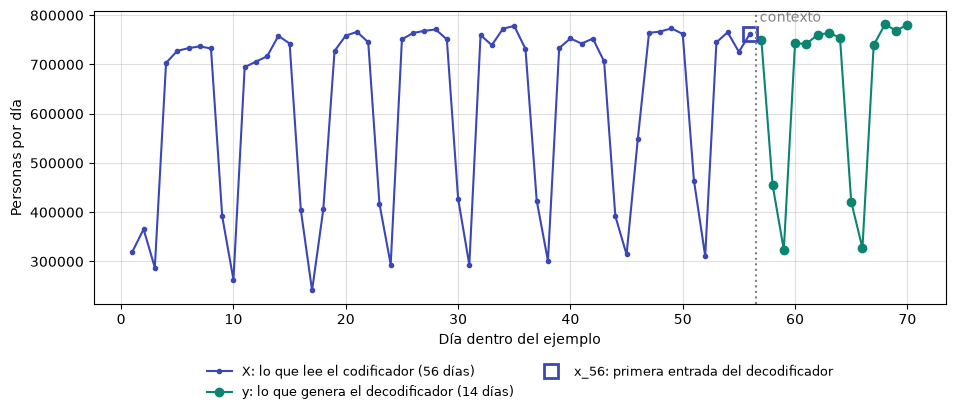

Forma de X: (56, 1)  Forma de y: (14,)


In [23]:
X, y = train_set_4[0]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(np.arange(1, 57), X[:, 0] * scale, "o-", color=INDIGO, ms=3, label="X: lo que lee el codificador (56 días)")
ax.plot(np.arange(57, 71), y * scale, "o-", color=TEAL, ms=6, label="y: lo que genera el decodificador (14 días)")
ax.plot(56, X[-1, 0] * scale, "s", color=INDIGO, ms=10, mfc="none", mew=2, label="x_56: primera entrada del decodificador")
ax.axvline(56.5, color="gray", ls=":")
ax.text(56.5, ax.get_ylim()[1], " contexto", va="top", color="gray")
ax.set_xlabel("Día dentro del ejemplo"); ax.set_ylabel("Personas por día"); ax.grid(alpha=0.4)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False, fontsize=9)
plt.show()
print("Forma de X:", tuple(X.shape), " Forma de y:", tuple(y.shape))

### La red

`EncoderDecoder` junta las dos partes:

- `self.encoder` es una `nn.GRU`, como la de `SeqToVector`: lee los 56 días de una vez. Su segundo resultado, `h_n`, es el último estado, con forma `(1, batch, 32)` (el 1 es el número de capas). `h_n[0]` le quita esa dimensión: es el contexto $c$, forma `(batch, 32)`. Frente a `SeqToVector`, aquí ya no hay capa densa después del codificador.
- `self.decoder` es **la misma clase `Decoder`** de vector → secuencia (pero un objeto nuevo, con sus propios pesos). Frente a `VectorToSeq` cambian sus dos primeros argumentos: el estado inicial es el contexto (en vez de `tanh(self.to_state(v))`) y la primera entrada es el último día conocido, `X[:, -1]`, que es $x_{56}$ con forma `(batch, 1)` (en vez de un cero).

In [24]:
class EncoderDecoder(nn.Module):
    def __init__(self, hidden_size=32, horizon=14):
        super().__init__()
        self.encoder = nn.GRU(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.decoder = Decoder(hidden_size)
        self.horizon = horizon

    def forward(self, X, target=None):
        outputs, h_n = self.encoder(X)     # h_n: (1, batch, 32), el último estado h_56
        context = h_n[0]                   # el contexto: (batch, 32)
        last_value = X[:, -1]              # x_56, lo que entra en el paso 1: (batch, 1)
        return self.decoder(context, last_value, self.horizon, target)


torch.manual_seed(42)
encoder_decoder = Forecaster(EncoderDecoder())
encoder_decoder.fit(train_set_4, valid_set_4, epochs=100)

Entrenamiento: 100%|██████████| 100/100 [00:11<00:00,  8.41época/s, mae=37,442, mejor_val_mae=46,675, val_mae=50,156]

Mejor MAE de validación: 46,675 personas


### El pronóstico

El mismo ejemplo de test. Ahora la red sí lee los 56 días en índigo (con el codificador) y genera los 14 días en rojo (con el decodificador), uno por uno.

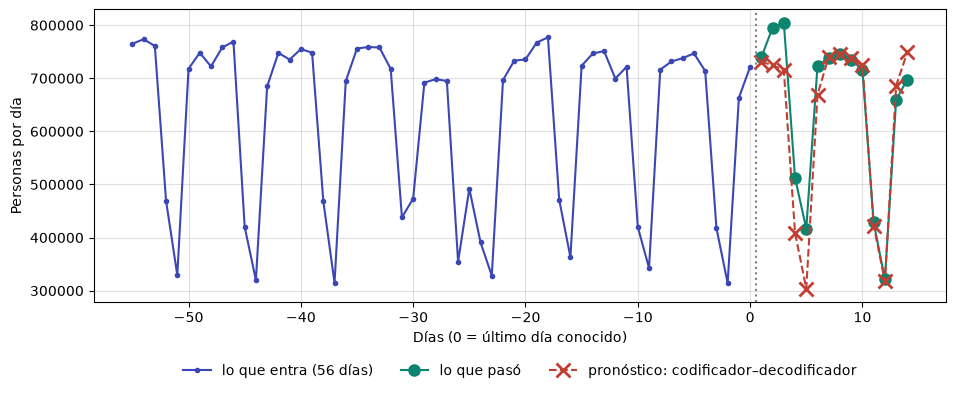

In [25]:
Y_encoder_decoder = encoder_decoder.predict(X_test)
plot_forecast(X_test, Y_test, Y_encoder_decoder, "pronóstico: codificador–decodificador")

Frente a vector → secuencia, esta red conoce lo que pasó en las últimas semanas y no solo un resumen escogido a mano; frente al paso a paso de la etapa 5, se entrenó para acertar en los 14 días y no solo en el primero. Una ventaja más: el número de días que genera no queda fijo en la capa de salida; el `for` del decodificador podría dar 7 o 21 pasos con la misma red (aunque se equivocaría más en los días que no practicó al entrenar).

## Etapa 8: ¿Cuál se equivoca menos en los 14 días?

Tenemos tres formas de pronosticar los 14 días que necesita la CTA:

| | Qué lee | Cómo salen los 14 días | Para qué se entrenó |
|---|---|---|---|
| Paso a paso (etapa 5) | los 56 días | la red de secuencia → vector, usada 14 veces con sus pronósticos | para dar **un** día |
| Vector → secuencia (etapa 6) | 9 números | uno por uno, con un decodificador | para dar los 14 días |
| Codificador–decodificador (etapa 7) | los 56 días | uno por uno, con un decodificador que parte del resumen de la historia | para dar los 14 días |

Para compararlas usamos todos los ejemplos de **test**, que ninguna red vio al entrenar. Como referencia incluimos otra vez el **pronóstico ingenuo**, ahora para 14 días: cada día futuro es igual al mismo día de la semana más reciente dentro de la ventana (el próximo lunes será igual al último lunes).

Medimos el MAE (error absoluto medio, en personas por día) **por separado para cada día del horizonte**: el error de pronosticar mañana (día 1), el de pasado mañana (día 2), …, el de dentro de 14 días (día 14). Así vemos cómo crece el error a medida que miramos más lejos.

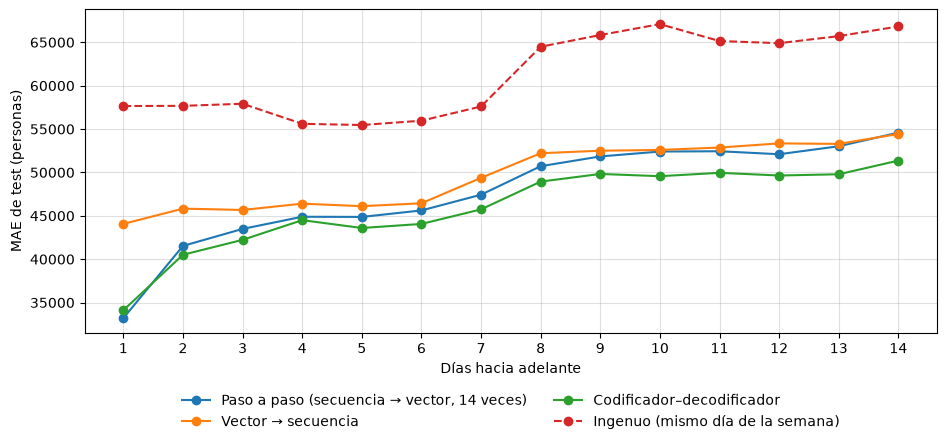

,MAE promedio de test (personas)
"Paso a paso (secuencia → vector, 14 veces)",47725
Vector → secuencia,49653
Codificador–decodificador,45988
Ingenuo (mismo día de la semana),61276


In [26]:
# Ingenuo: el día h se pronostica con el mismo día de la semana dentro de la última semana de la ventana
Y_naive = torch.stack([X_test[:, -7 + (h % 7), 0] for h in range(horizon)], dim=1)

forecasts = {
    "Paso a paso (secuencia → vector, 14 veces)": Y_step_by_step,
    "Vector → secuencia": Y_vector_to_seq,
    "Codificador–decodificador": Y_encoder_decoder,
    "Ingenuo (mismo día de la semana)": Y_naive,
}
days = np.arange(1, horizon + 1)
fig, ax = plt.subplots(figsize=(11, 4.2))
summary = {}
for name, Y_pred in forecasts.items():
    errors = ((Y_pred - Y_test).abs().mean(dim=0) * scale).numpy()   # MAE de cada día del horizonte
    summary[name] = errors.mean()
    ax.plot(days, errors, marker="o", ls="--" if name.startswith("Ingenuo") else "-", label=name)
ax.set_xlabel("Días hacia adelante"); ax.set_ylabel("MAE de test (personas)")
ax.set_xticks(days); ax.grid(alpha=0.4)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
plt.show()

pd.Series(summary, name="MAE promedio de test (personas)").round().astype(int).to_frame()

Para leer la gráfica y la tabla (los números cambian un poco en cada ejecución):

- **Las tres formas le ganan al pronóstico ingenuo** en todos los días del horizonte.
- **El error crece a medida que miramos más lejos:** pronosticar mañana es más fácil que pronosticar dentro de dos semanas, para todas.
- **Paso a paso:** en el día 1 es tan buena como la mejor, porque ahí es simplemente la red de secuencia → vector leyendo datos reales. Pero desde el día 2 su error sube más rápido que el del codificador–decodificador: cada día lee más pronósticos suyos y menos datos reales, y la red nunca se entrenó para eso. Es la acumulación de errores que vimos en la presentación.
- **Vector → secuencia** es la que más se equivoca en los primeros días: solo conoce el día de la semana, el mes y el promedio de la última semana, no lo que pasó ayer. Aun así le gana con claridad al ingenuo. Es la arquitectura para cuando no hay una historia que leer, solo una descripción de la situación.
- **Codificador–decodificador** queda con el menor error a partir del día 2: lee toda la historia, como el paso a paso, y además se entrenó para generar los 14 días, como vector → secuencia.

En resumen, con las cuatro arquitecturas usamos siempre las mismas piezas: una GRU que lee la serie, una capa densa que convierte un estado en un pronóstico, y un decodificador que genera un valor por paso. Lo que cambia de una arquitectura a otra es **qué entra, qué sale y cuándo sale**.